# A two-layer network and backpropagation in NumPy

I build a `2 → 8 → 1` network (tanh hidden layer, sigmoid output) in NumPy, derive and code its backward pass, train it with gradient descent on the two-moons dataset, and check the gradients against finite differences and PyTorch autograd. Then I change one thing at a time: the hidden width, the hidden nonlinearity, the learning rate, and the number of hidden layers.

**Results**

- The backward pass matches centred finite differences with relative errors below $2\cdot10^{-9}$ for every parameter array, and PyTorch autograd to about $10^{-17}$.
- The baseline (lr 0.05, 3000 epochs) reaches 88.3% train and 93.0% test accuracy.
- Every run first stalls near the loss of the best straight line (about 0.29), then bends its boundary. With width 2, 8 and 32 the test accuracy after 3000 epochs is 91%, 95.5% and 98%.
- With the identity instead of tanh, the network collapses to logistic regression: a straight boundary, train loss stuck at 0.283, 91% test accuracy.
- The learning rate changes how fast the model leaves the plateau. lr 0.05 for 30,000 epochs ends at the same train loss (0.0284) as lr 0.5 for 3000. The same lr 0.5 on inputs multiplied by 30 never settles.
- A second hidden layer (105 parameters against 33) gets 99% test accuracy after 4000 epochs, against 96.5% for one layer. The one-layer model reaches 100% with lr 0.5, so here the gap comes from optimization speed.

**Environment:** NumPy and scikit-learn on a CPU. PyTorch is used only for the autograd checks.

## 1. Setup

NumPy for the network, Matplotlib for plots, and scikit-learn only to make and split the dataset.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

np.random.seed(42)

plt.rcParams["figure.figsize"] = (7, 5)
plt.rcParams["axes.grid"] = True

## 2. Create a nonlinear dataset

We use the **two-moons** dataset. A linear classifier cannot separate the two classes perfectly, so a hidden layer is useful.

Each example has two input features:

$$
x = [x_1, x_2]
$$

and a binary label:

$$
y \in \{0,1\}
$$

### Why two moons

Each example is a point in the plane, so the two features $x_1$ and $x_2$ are its coordinates. The label says which moon the point came from. Class 0 is the upper half circle of radius 1 centred at $(0, 0)$, and class 1 is the lower half circle centred at $(1, 0.5)$. `make_moons` then adds Gaussian noise with standard deviation `noise=0.15` to both coordinates. With 1000 samples there are 500 per class, and the stratified split keeps both sets balanced (400/400 for training, 100/100 for test).

The two moons interlock: the end of each moon reaches into the hollow of the other, so every straight line leaves part of one moon on the wrong side. A linear classifier gets about 86% here (Section 18), while a network with a hidden layer can bend its boundary around the moons. Because the data is 2-D, we can also draw the boundary and see what the hidden layer changed.

Gaussian noise has no bound, so a point from one moon can land inside the other moon's region. Where the two noisy distributions overlap, the same $x$ can come from either class, and no classifier can be right on every point of the distribution (the Bayes error is above zero). A very wiggly boundary can still separate one finite training sample by memorising its noisy points, but that boundary would not carry over to new data.

X_train: (800, 2)
y_train: (800,)
X_test : (200, 2)
y_test : (200,)


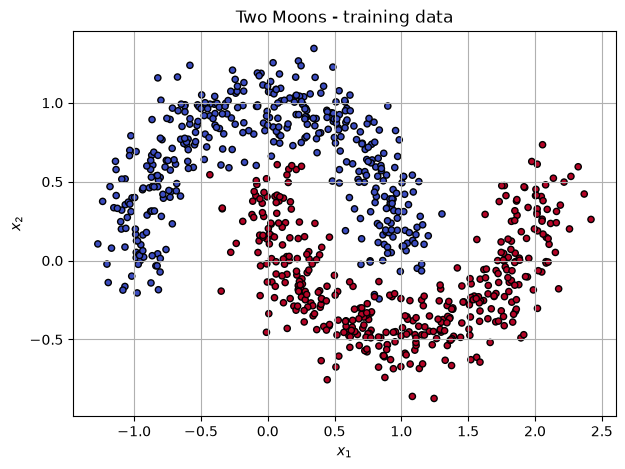

In [2]:
X, y = make_moons(n_samples=1000, noise=0.15, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="coolwarm", edgecolors="k", s=20)
plt.title("Two Moons - training data")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.show()

## 3. Neural Network Architecture

The network:

$$
\boxed{2 \rightarrow 8 \rightarrow 1}
$$

- **Input layer:** 2 neurons
- **Hidden layer:** 8 neurons
- **Output layer:** 1 neuron
- **Hidden activation:** $\tanh$
- **Output activation:** Sigmoid

The forward pass is defined as follows:

$$
Z^{[1]} = XW^{[1]} + b^{[1]}
$$

$$
A^{[1]} = \tanh(Z^{[1]})
$$

$$
Z^{[2]} = A^{[1]}W^{[2]} + b^{[2]}
$$

$$
A^{[2]} = \sigma(Z^{[2]})
$$

where the sigmoid function is defined as:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

In [3]:
input_size = 2
hidden_size = 8
output_size = 1
print(f"Architecture: {input_size} -> {hidden_size} -> {output_size}")

Architecture: 2 -> 8 -> 1


## 4. Activation functions

We need two activation functions.

### Tanh

$$
\tanh(x)
$$

Its derivative can be written as:

$$
\frac{d}{dx}\tanh(x) = 1 - \tanh^2(x)
$$

### Sigmoid

$$
\sigma(x)=\frac{1}{1+e^{-x}}
$$

Its derivative is:

$$
\sigma'(x)=\sigma(x)(1-\sigma(x))
$$

### Why the hidden layer needs a nonlinearity

Without a nonlinearity every layer is an affine map, and a composition of affine maps is still affine:

$$(XW^{[1]}+b^{[1]})W^{[2]}+b^{[2]} = X\,W^{[1]}W^{[2]} + (b^{[1]}W^{[2]}+b^{[2]}).$$

Any number of such layers equals one linear layer, so the hidden layer would add parameters but no new functions.

| | sigmoid | tanh | ReLU |
|---|---|---|---|
| range | $(0, 1)$ | $(-1, 1)$ | $[0, \infty)$ |
| derivative | $\sigma(z)(1-\sigma(z))$, at most 0.25 | $1-\tanh^2(z)$, at most 1 | 0 for $z<0$, 1 for $z>0$ |
| saturates | for large $\lvert z\rvert$ on both sides | for large $\lvert z\rvert$ on both sides | only for $z<0$ |

Sigmoid gives a probability, which is why we keep it at the output. In hidden layers its outputs are not zero-centred, and its derivative is at most 0.25, so the gradient shrinks at every layer and almost vanishes once $|z|$ is large.

Tanh is a rescaled sigmoid, $\tanh(z) = 2\sigma(2z)-1$. It is zero-centred and its derivative is 1 at $z=0$, so in hidden layers it usually trains faster than sigmoid. It saturates in the same way, though.

ReLU is cheap and does not saturate for positive inputs, so gradients pass through deep networks well. A unit whose input stays negative gets zero gradient and can stop learning for good (a "dead" ReLU). Its output is also unbounded and not zero-centred.

Hypothesis (tested in Section 18): if the hidden tanh is replaced with the identity, the network becomes logistic regression on $(x_1, x_2)$. The boundary will be a straight line however wide the hidden layer is. The training loss will flatten early at a higher value than the tanh model's, and accuracy will stay clearly lower because the ends of the moons fall on the wrong side of the line.

In [4]:
def sigmoid(z):
    # Never call exp on a large positive number: for z < 0 use e^z / (1 + e^z).
    z = np.asarray(z, dtype=np.float64)
    out = np.empty_like(z)
    positive = z >= 0
    out[positive] = 1.0 / (1.0 + np.exp(-z[positive]))
    exp_z = np.exp(z[~positive])
    out[~positive] = exp_z / (1.0 + exp_z)
    return out


def tanh(z):
    return np.tanh(z)


def tanh_derivative(z):
    return 1.0 - np.tanh(z) ** 2

## 5. Initialize the parameters

The parameters are:

$$
W^{[1]}, b^{[1]}, W^{[2]}, b^{[2]}
$$

Their shapes are:
$$
W^{[1]}: (2,8)
$$
$$
b^{[1]}: (1,8)
$$
$$
W^{[2]}: (8,1)
$$
$$
b^{[2]}: (1,1)
$$

We use small random values for the weights and zeros for the biases.

In [5]:
W1 = np.random.randn(input_size, hidden_size) * 0.5
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size) * 0.5
b2 = np.zeros((1, output_size))

for name, value in (("W1", W1), ("b1", b1), ("W2", W2), ("b2", b2)):
    print(f"{name}: {value.shape}")

W1: (2, 8)
b1: (1, 8)
W2: (8, 1)
b2: (1, 1)


## 6. Forward propagation

For a batch of examples, the computations are:

### Layer 1

$$
Z^{[1]} = XW^{[1]} + b^{[1]}
$$

$$
A^{[1]} = \tanh(Z^{[1]})
$$

### Layer 2

$$
Z^{[2]} = A^{[1]}W^{[2]} + b^{[2]}
$$

$$
A^{[2]} = \sigma(Z^{[2]})
$$

The output $(\hat{Y})$ represents the predicted probability that an example belongs to class 1.

`forward(X, W1, b1, W2, b2)` returns probabilities of shape `(m, 1)` and a cache with `X`, `Z1`, `A1`, `Z2` and `A2` for the backward pass.

In [6]:
def forward(X, W1, b1, W2, b2):
    Z1 = X @ W1 + b1          # (m, 8)
    A1 = tanh(Z1)             # (m, 8)
    Z2 = A1 @ W2 + b2         # (m, 1)
    A2 = sigmoid(Z2)          # (m, 1)
    cache = {"X": X, "Z1": Z1, "A1": A1, "Z2": Z2, "A2": A2}
    return A2, cache


predictions, cache = forward(X_train, W1, b1, W2, b2)
print("Prediction shape:", predictions.shape)
print("First 5 predictions:", predictions[:5])

Prediction shape: (800, 1)
First 5 predictions: [[0.38519622]
 [0.50134302]
 [0.15925899]
 [0.70451376]
 [0.15521848]]


## 7. Binary cross-entropy loss

For binary classification, we use:

$$
L =
-\frac{1}{m}
\sum_{i=1}^{m}
\left[
y_i\log(\hat{y}_i)
+
(1-y_i)\log(1-\hat{y}_i)
\right]
$$

where:
- $m$ is the number of training examples.
- $(y_i)$ is the true label.
- $(\hat{y}_i)$ is the predicted probability.
A small loss means that the predictions are close to the true labels.

In [7]:
def binary_cross_entropy(y_true, y_pred):
    eps = 1e-12
    y_true = np.asarray(y_true, dtype=np.float64).reshape(-1, 1)
    y_pred = np.clip(np.asarray(y_pred, dtype=np.float64).reshape(-1, 1), eps, 1 - eps)
    return float(-np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred)))


loss = binary_cross_entropy(y_train, predictions)
print("Initial loss:", loss)

Initial loss: 1.2013441229693191


## 8. Backpropagation

Below I derive every gradient from the mean binary cross-entropy with the chain rule, give its shape, and show where the factor $1/m$ enters. `backward(y_true, cache, W2)` then returns `dW1`, `db1`, `dW2` and `db2`. The derivation assumes the sigmoid outputs stay inside the loss clipping interval, which holds for the parameters used in the gradient check.

For one example write $z = Z^{[2]}_i$ and $a = A^{[2]}_i = \sigma(z)$. Its loss is $\ell_i = -[y_i\log a + (1-y_i)\log(1-a)]$, and $L = \frac{1}{m}\sum_i \ell_i$.

**Output layer.**

$$\frac{\partial \ell_i}{\partial a} = -\frac{y_i}{a} + \frac{1-y_i}{1-a} = \frac{a-y_i}{a(1-a)}, \qquad \frac{\partial a}{\partial z} = a(1-a).$$

The two $a(1-a)$ factors cancel, so

$$dZ^{[2]} = A^{[2]} - Y \qquad (m\times1).$$

This is the per-example derivative $\partial\ell_i/\partial Z^{[2]}_i$. The derivative of the mean loss is $dZ^{[2]}/m$. Since $Z^{[2]} = A^{[1]}W^{[2]} + b^{[2]}$,

$$dW^{[2]} = \frac{1}{m}A^{[1]T}dZ^{[2]} \quad (8\times1), \qquad db^{[2]} = \frac{1}{m}\sum_{i=1}^{m} dZ^{[2]}_{i} \quad (1\times1).$$

**Hidden layer.** The error goes back through $W^{[2]}$ and then through tanh:

$$dA^{[1]} = dZ^{[2]}W^{[2]T} \quad (m\times8), \qquad dZ^{[1]} = dA^{[1]} \odot \left(1-\tanh^2(Z^{[1]})\right) \quad (m\times8),$$

$$dW^{[1]} = \frac{1}{m}X^{T}dZ^{[1]} \quad (2\times8), \qquad db^{[1]} = \frac{1}{m}\sum_{i=1}^{m} dZ^{[1]}_{i,:} \quad (1\times8).$$

Every gradient has the shape of its parameter: $dW^{[1]}$ is $2\times8$, $db^{[1]}$ is $1\times8$, $dW^{[2]}$ is $8\times1$ and $db^{[2]}$ is $1\times1$.

**Where $1/m$ enters.** $L$ is the mean of $m$ per-example losses, so each example's share of a parameter gradient is weighted by $1/m$. I keep $dZ^{[2]}$, $dA^{[1]}$ and $dZ^{[1]}$ per example. The division by $m$ happens only where the examples are summed into a parameter gradient: in the products $A^{[1]T}dZ^{[2]}$ and $X^TdZ^{[1]}$, and in the bias sums. If $dZ^{[2]}$ were also divided by $m$, the factor would be applied twice and the gradients would be $m$ times too small.

**Why bias gradients sum over the batch.** In $Z = XW + b$ the same row $b$ is broadcast and added to all $m$ rows. Each row is a separate path from $b$ to the loss, and the chain rule adds the contributions of all paths, so $db$ is the sum of the rows of $dZ$, times $1/m$. The weight gradient also sums over examples; there the matrix product $X^TdZ$ does the sum.

These formulas assume $A^{[2]}$ is inside the clipping interval $[10^{-12}, 1-10^{-12}]$. Outside it the clipped loss is flat, and its true gradient would be zero.

In [8]:
def backward(y_true, cache, W2):
    X, Z1, A1, A2 = cache["X"], cache["Z1"], cache["A1"], cache["A2"]
    m = X.shape[0]
    Y = np.asarray(y_true, dtype=np.float64).reshape(-1, 1)

    dZ2 = A2 - Y                                      # (m, 1), per example, not averaged
    dW2 = A1.T @ dZ2 / m                              # (8, 1)
    db2 = np.sum(dZ2, axis=0, keepdims=True) / m      # (1, 1)

    dA1 = dZ2 @ W2.T                                  # (m, 8)
    dZ1 = dA1 * tanh_derivative(Z1)                   # (m, 8)
    dW1 = X.T @ dZ1 / m                               # (2, 8)
    db1 = np.sum(dZ1, axis=0, keepdims=True) / m      # (1, 8)

    return {"dW1": dW1, "db1": db1, "dW2": dW2, "db2": db2}


grads = backward(y_train, cache, W2)
for name, value in grads.items():
    print(name, value.shape)

dW1 (2, 8)
db1 (1, 8)
dW2 (8, 1)
db2 (1, 1)


## 9. Gradient descent

Once we have the gradients, we update each parameter:

$$
W \leftarrow W - \eta\frac{\partial L}{\partial W}
$$

where $\eta$ is the learning rate.

We repeat this process:

**forward → loss → backward → update**

until the model learns a useful representation of the data.

`train_model` runs forward → mean loss → backward → update of all four parameters in each epoch and records the loss before each update. It copies the initial arrays, so experiments cannot overwrite each other, and takes `forward_fn` and `backward_fn` so that Section 18 can reuse it with an identity hidden layer.

In [9]:
def train_model(X, y, initial_parameters, learning_rate=0.05, epochs=3000,
                forward_fn=forward, backward_fn=backward):
    parameters = {name: value.copy() for name, value in initial_parameters.items()}
    loss_history = np.zeros(epochs)
    for epoch in range(epochs):
        y_hat, cache = forward_fn(X, parameters["W1"], parameters["b1"],
                                  parameters["W2"], parameters["b2"])
        loss_history[epoch] = binary_cross_entropy(y, y_hat)
        grads = backward_fn(y, cache, parameters["W2"])
        for name in ("W1", "b1", "W2", "b2"):
            parameters[name] -= learning_rate * grads["d" + name]
    return parameters, loss_history


learning_rate = 0.05
epochs = 3000
initial_parameters = {"W1": W1.copy(), "b1": b1.copy(), "W2": W2.copy(), "b2": b2.copy()}
parameters, loss_history = train_model(X_train, y_train, initial_parameters,
                                      learning_rate=learning_rate, epochs=epochs)
W1, b1, W2, b2 = (parameters[name] for name in ("W1", "b1", "W2", "b2"))
for epoch in range(0, epochs, 500):
    print(f"Epoch {epoch:4d} | Loss = {loss_history[epoch]:.4f}")

Epoch    0 | Loss = 1.2013
Epoch  500 | Loss = 0.2945
Epoch 1000 | Loss = 0.2896
Epoch 1500 | Loss = 0.2878
Epoch 2000 | Loss = 0.2845
Epoch 2500 | Loss = 0.2753


## 10. Visualize the training loss

The loss should generally decrease as training progresses.

A decreasing loss indicates that gradient descent is finding parameter values that make the model's predictions closer to the training labels.

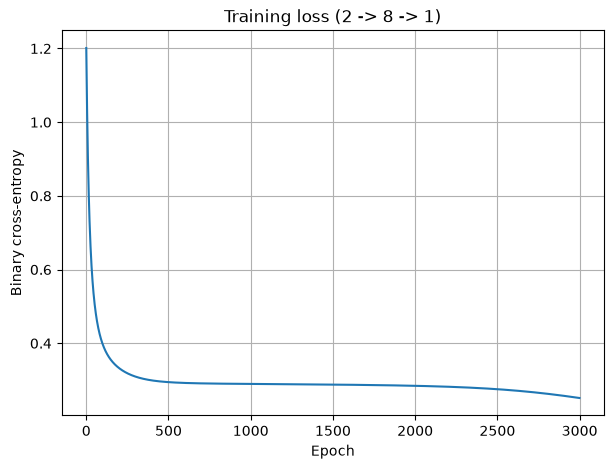

In [10]:
plt.plot(np.arange(len(loss_history)), loss_history)
plt.title("Training loss (2 -> 8 -> 1)")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy")
plt.show()

## 11. Evaluate the model

For binary classification, we convert probabilities into class predictions:

$$
prediction =
\begin{cases}
1 & \hat{y} \ge 0.5\\
0 & \hat{y} < 0.5
\end{cases}
$$

In [11]:
def predict(X):
    probabilities, _ = forward(X, W1, b1, W2, b2)
    return (probabilities >= 0.5).astype(int).ravel()


train_accuracy = np.mean(predict(X_train) == y_train)
test_accuracy = np.mean(predict(X_test) == y_test)
print(f"Train accuracy: {train_accuracy:.4f}")
print(f"Test accuracy : {test_accuracy:.4f}")

Train accuracy: 0.8825
Test accuracy : 0.9300


## 12. Visualize the decision boundary

The hidden layer allows the network to learn a **nonlinear decision boundary**.

We create a grid of points and ask the network for its predicted probability at every point.

`plot_decision_boundary` evaluates the model on a 300×300 grid, draws the probability contours and the 0.5 boundary, and overlays the data. It takes an optional `ax` so that later comparisons can share one figure.

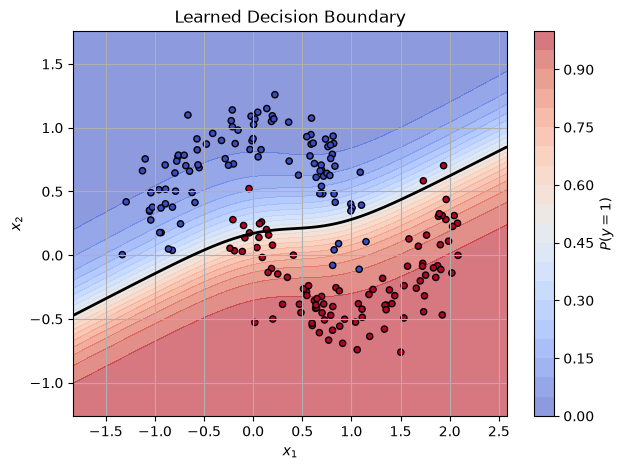

<Axes: title={'center': 'Learned Decision Boundary'}, xlabel='$x_1$', ylabel='$x_2$'>

In [12]:
def plot_decision_boundary(X, y, model_predict_proba, ax=None, title="Learned Decision Boundary"):
    standalone = ax is None
    if standalone:
        _, ax = plt.subplots()

    pad = 0.5
    x1 = np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, 300)
    x2 = np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, 300)
    xx1, xx2 = np.meshgrid(x1, x2)
    grid = np.c_[xx1.ravel(), xx2.ravel()]
    probabilities = np.asarray(model_predict_proba(grid)).reshape(xx1.shape)

    filled = ax.contourf(xx1, xx2, probabilities, levels=np.linspace(0, 1, 21),
                         cmap="coolwarm", alpha=0.6)
    ax.contour(xx1, xx2, probabilities, levels=[0.5], colors="k", linewidths=2)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k", s=20)
    ax.set(title=title, xlabel="$x_1$", ylabel="$x_2$")

    if standalone:
        plt.colorbar(filled, ax=ax, label="$P(y=1)$")
        plt.show()
    return ax


def predict_proba(X):
    probabilities, _ = forward(X, W1, b1, W2, b2)
    return probabilities.ravel()


plot_decision_boundary(X_test, y_test, predict_proba)

## 13. What exactly happens during one training step?

The complete learning process can be summarized as:

```text
Input X
  │
  ▼
Linear transformation
Z1 = XW1 + b1
  │
  ▼
Tanh
A1 = tanh(Z1)
  │
  ▼
Linear transformation
Z2 = A1W2 + b2
  │
  ▼
Sigmoid
ŷ = sigmoid(Z2)
  │
  ▼
Binary Cross-Entropy
  │
  ▼
Loss L
  │
  ▼
Backpropagation
  │
  ├── dW2, db2
  │
  └── dW1, db1
        │
        ▼
Gradient Descent
        │
        ▼
Updated parameters
```

The important idea is that **backpropagation is the efficient application of the chain rule**.

## 14. Gradient checking

`check_gradients(parameters, analytical_grads, loss_fn, epsilon=1e-5)` perturbs every entry $\theta_j$ of `W1`, `b1`, `W2` and `b2`, restores it afterwards, and computes
$$g_j^{\mathrm{num}}=\frac{L(\theta_j+\epsilon)-L(\theta_j-\epsilon)}{2\epsilon}.$$
For each array it reports
$$\mathrm{error}=\frac{\lVert g^{\mathrm{analytical}}-g^{\mathrm{numerical}}\rVert_2}
{\lVert g^{\mathrm{analytical}}\rVert_2+\lVert g^{\mathrm{numerical}}\rVert_2+10^{-12}}.$$
I run it in float64 at the trained parameters, where all probabilities are inside the clipping interval, and require every error to be below $10^{-6}$. Section 20 reuses the same checker for the six arrays of the deeper network.

In [13]:
def check_gradients(parameters, analytical_grads, loss_fn, epsilon=1e-5):
    errors = {}
    for name, theta in parameters.items():
        assert theta.dtype == np.float64, f"{name} must be float64"
        numerical = np.zeros_like(theta)
        for index in np.ndindex(theta.shape):
            original = theta[index]
            theta[index] = original + epsilon
            loss_plus = loss_fn(parameters)
            theta[index] = original - epsilon
            loss_minus = loss_fn(parameters)
            theta[index] = original                      # restore
            numerical[index] = (loss_plus - loss_minus) / (2 * epsilon)
        analytical = analytical_grads["d" + name]
        errors[name] = (np.linalg.norm(analytical - numerical)
                        / (np.linalg.norm(analytical) + np.linalg.norm(numerical) + 1e-12))
    return errors


check_parameters = {name: value.copy() for name, value in parameters.items()}
_, check_cache = forward(X_train, **check_parameters)
# The clipping in the loss is inactive here, so the analytical gradient is the true one.
print(f"Probability range: [{check_cache['A2'].min():.6f}, {check_cache['A2'].max():.6f}]")
analytical_grads = backward(y_train, check_cache, check_parameters["W2"])
gradient_errors = check_gradients(
    check_parameters, analytical_grads,
    lambda p: binary_cross_entropy(y_train, forward(X_train, **p)[0]))
for name, error in gradient_errors.items():
    print(f"{name}: relative error = {error:.12e}")
    assert error < 1e-6, f"Gradient check failed for {name}"

Probability range: [0.009050, 0.991098]
W1: relative error = 2.728391749859e-10
b1: relative error = 2.119621083298e-10
W2: relative error = 1.064997739899e-10
b2: relative error = 1.854330193005e-09


## 15. Comparison with PyTorch autograd

The same trained parameters, examples and mean loss go into a float64 PyTorch model (weights transposed, no retraining), and I compare the predictions and all four gradient arrays.

In [14]:
import torch

model = torch.nn.Sequential(
    torch.nn.Linear(W1.shape[0], W1.shape[1]),
    torch.nn.Tanh(),
    torch.nn.Linear(W2.shape[0], W2.shape[1]),
    torch.nn.Sigmoid()
).double()
with torch.no_grad():
    for layer, weight, bias in ((model[0], W1, b1), (model[2], W2, b2)):
        layer.weight.copy_(torch.from_numpy(weight.T))
        layer.bias.copy_(torch.from_numpy(bias.ravel()))
X_t = torch.tensor(X_train, dtype=torch.float64)
y_t = torch.tensor(y_train.reshape(-1, 1), dtype=torch.float64)
torch_output = model(X_t)
torch_loss = torch.nn.BCELoss()(torch_output, y_t)
model.zero_grad()
torch_loss.backward()
numpy_output, cache = forward(X_train, W1, b1, W2, b2)
numpy_grads = backward(y_train, cache, W2)
torch_grads = {"dW1": model[0].weight.grad.numpy().T,
               "db1": model[0].bias.grad.numpy().reshape(1, -1),
               "dW2": model[2].weight.grad.numpy().T,
               "db2": model[2].bias.grad.numpy().reshape(1, -1)}
np.testing.assert_allclose(numpy_output, torch_output.detach().numpy(), atol=1e-12, rtol=1e-10)
torch_errors = {}
for name in numpy_grads:
    torch_errors[name] = np.max(np.abs(numpy_grads[name] - torch_grads[name]))
    print(f"{name}: maximum autograd difference = {torch_errors[name]:.12e}")
    np.testing.assert_allclose(numpy_grads[name], torch_grads[name], atol=1e-10, rtol=1e-8)

dW1: maximum autograd difference = 1.734723475977e-17
db1: maximum autograd difference = 2.949029909161e-17
dW2: maximum autograd difference = 3.469446951954e-18
db2: maximum autograd difference = 4.119968255445e-18


## 16. Setup for the comparisons

Each of the next four sections changes one thing about the baseline. `initialize_parameters` creates fresh models from seed 17, and `show_experiments` prints train/test loss and accuracy and draws the loss curves and test-set boundaries side by side. Within a comparison, the split, seed, number of epochs and learning rate stay fixed unless they are the thing being varied.

In [15]:
def initialize_parameters(hidden_width, seed=17):
    rng = np.random.RandomState(seed)
    return {"W1": rng.randn(2, hidden_width) * 0.5,
            "b1": np.zeros((1, hidden_width)),
            "W2": rng.randn(hidden_width, 1) * 0.5,
            "b2": np.zeros((1, 1))}


def show_experiments(runs):
    fig, axes = plt.subplots(2, len(runs), figsize=(5 * len(runs), 8),
                             squeeze=False, sharey="row")
    metrics = {}
    for column, (label, run) in enumerate(runs.items()):
        predict_fn = run["predict"]
        train_prob = predict_fn(X_train).reshape(-1, 1)
        test_prob = predict_fn(X_test).reshape(-1, 1)
        metrics[label] = {
            "train_loss": binary_cross_entropy(y_train, train_prob),
            "test_loss": binary_cross_entropy(y_test, test_prob),
            "train_accuracy": np.mean((train_prob.ravel() >= 0.5) == y_train),
            "test_accuracy": np.mean((test_prob.ravel() >= 0.5) == y_test)}
        print(label, " | ".join(f"{key}={value:.4f}" for key, value in metrics[label].items()))
        axes[0, column].plot(run["loss"])
        axes[0, column].set(title=label, xlabel="Epoch", ylabel="Training BCE")
        plot_decision_boundary(X_test, y_test, predict_fn, ax=axes[1, column], title=label)
    plt.tight_layout()
    plt.show()
    return metrics

## 17. Hidden width

Fresh `2 → h → 1` models with h = 2, 8 and 32 (seed 17, lr 0.05, 3000 epochs, tanh hidden layer, sigmoid output). Does a wider hidden layer give better test accuracy, and is the difference about capacity or about optimization?

width=2 train_loss=0.2915 | test_loss=0.2111 | train_accuracy=0.8638 | test_accuracy=0.9100
width=8 train_loss=0.1866 | test_loss=0.1348 | train_accuracy=0.9213 | test_accuracy=0.9550
width=32 train_loss=0.1024 | test_loss=0.0735 | train_accuracy=0.9712 | test_accuracy=0.9800


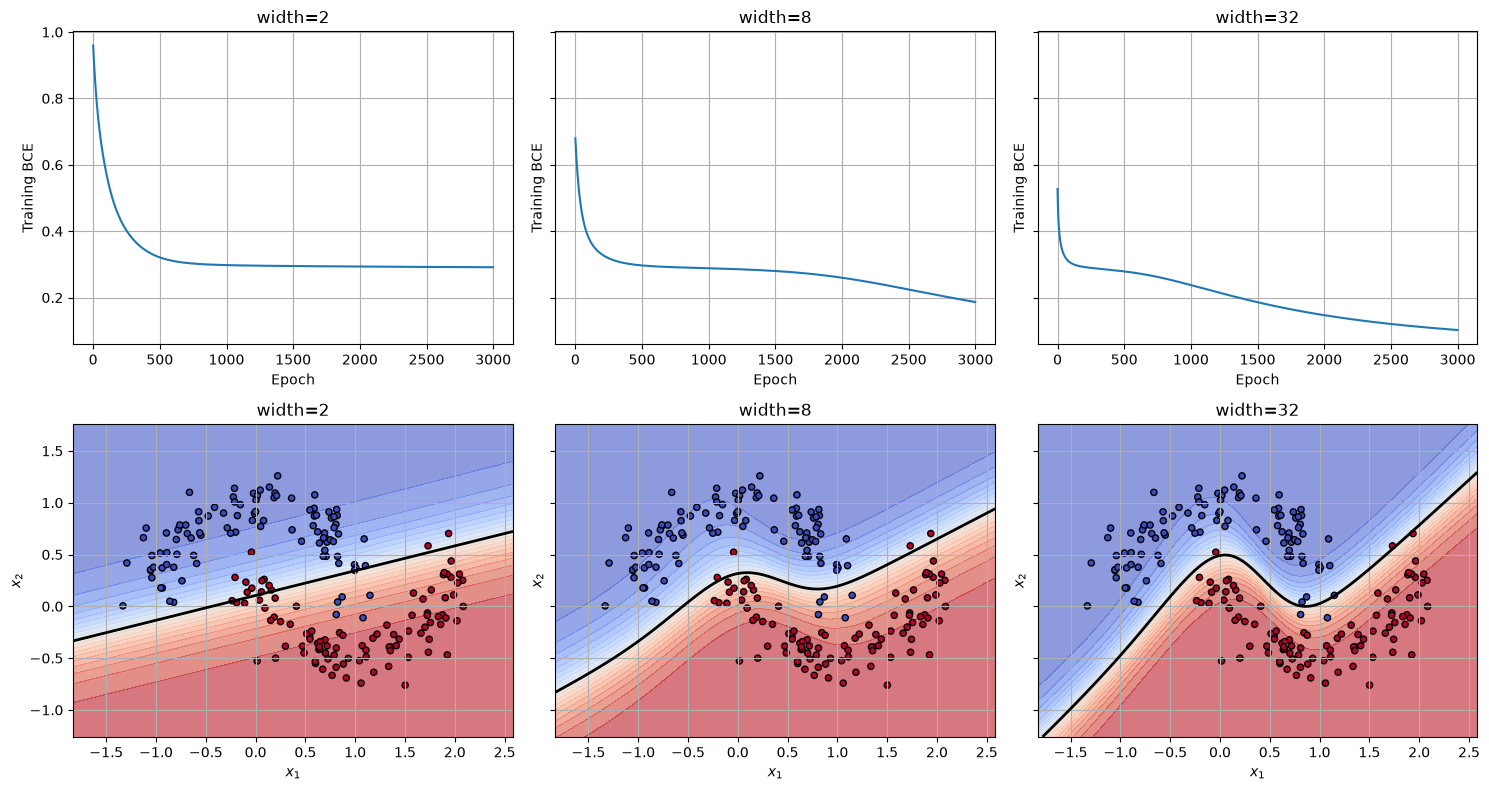

In [16]:
width_runs = {}
for h in (2, 8, 32):
    params, loss = train_model(X_train, y_train, initialize_parameters(h, seed=17),
                               learning_rate=0.05, epochs=3000)
    width_runs[f"width={h}"] = {
        "parameters": params,
        "loss": loss,
        "predict": lambda X, p=params: forward(X, **p)[0].ravel()}

width_metrics = show_experiments(width_runs)

| width | train loss | test loss | train acc | test acc |
|---|---|---|---|---|
| 2 | 0.2915 | 0.2111 | 0.8638 | 0.9100 |
| 8 | 0.1866 | 0.1348 | 0.9213 | 0.9550 |
| 32 | 0.1024 | 0.0735 | 0.9712 | 0.9800 |

All three loss curves first drop to about 0.29 and then flatten. That level is close to the best straight-line fit (the identity model in Section 18 stops at 0.2832), so on this plateau each network acts almost like a linear classifier. The width-2 model never leaves the plateau. Its boundary is nearly straight, and its train accuracy of 0.8638 is exactly that of the identity model. The width-8 model leaves the plateau around epoch 1500 and starts to bend its boundary between the moons; its loss is still falling at epoch 3000. The width-32 model leaves the plateau before epoch 500 and draws the clearest S-shaped boundary.

Capacity is the set of functions a model can represent. Each tanh unit adds one soft step to the logit, so more units allow a boundary with more bends. Two units can already bend the line a little, so the width-2 result is partly an optimization failure: it did not find a curved solution in 3000 epochs. Width also helped optimization here, because the wider models left the plateau sooner. With a fixed budget of 3000 epochs the comparison mixes both effects, and the width-8 model is simply not finished.

Greater width does not necessarily improve test accuracy. It did here because the moon shape is simple and no model came close to fitting the noise (the best train accuracy is 0.97). A much wider network trained for long enough could bend around single noisy points in the overlap, which raises train accuracy and lowers test accuracy. The test set is also small. One test point is 0.5%, so 0.955 against 0.98 is a difference of 5 points. The small test set probably also explains why test accuracy is above train accuracy in every run: these 200 points happen to contain fewer points from the overlap region.

## 18. Removing the hidden nonlinearity

Two width-8 models start from identical initial arrays (seed 17, lr 0.05, 3000 epochs). The first keeps tanh. In the second, only the hidden tanh is replaced with the identity, $A^{[1]}=Z^{[1]}$; the output sigmoid and the binary cross-entropy stay. `forward_identity` and `backward_identity` implement it, with the identity's derivative of 1 in the backward pass, and both models use the same training loop.

tanh hidden train_loss=0.1866 | test_loss=0.1348 | train_accuracy=0.9213 | test_accuracy=0.9550
identity hidden train_loss=0.2832 | test_loss=0.2021 | train_accuracy=0.8638 | test_accuracy=0.9100


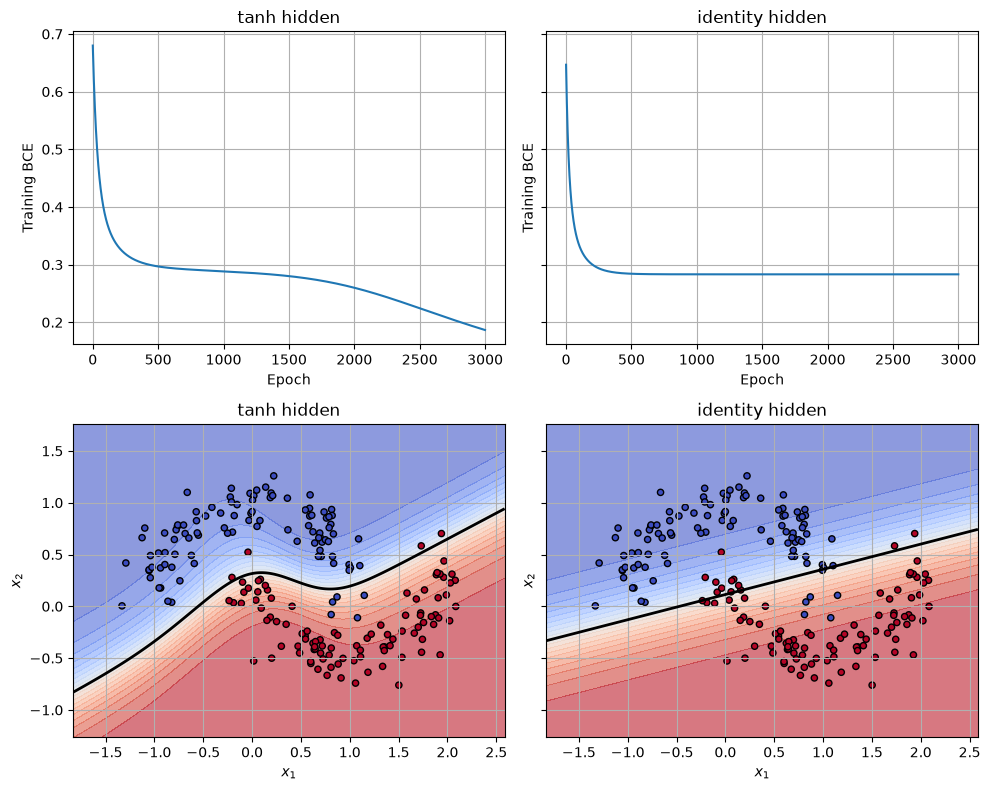

Identity-hidden gradient errors: {'W1': 3.6652632190085334e-11, 'b1': 1.4195242571075004e-10, 'W2': 1.623008808675445e-11, 'b2': 5.866529807295105e-11}
Collapsed logit: z = 1.2301*x1 -5.0575*x2 +0.5766
0.5 boundary (z = 0): x2 = 0.2432*x1 +0.1140


In [17]:
def forward_identity(X, W1, b1, W2, b2):
    Z1 = X @ W1 + b1
    A1 = Z1                      # identity instead of tanh
    Z2 = A1 @ W2 + b2
    A2 = sigmoid(Z2)
    cache = {"X": X, "Z1": Z1, "A1": A1, "Z2": Z2, "A2": A2}
    return A2, cache


def backward_identity(y_true, cache, W2):
    X, A1, A2 = cache["X"], cache["A1"], cache["A2"]
    m = X.shape[0]
    Y = np.asarray(y_true, dtype=np.float64).reshape(-1, 1)

    dZ2 = A2 - Y
    dW2 = A1.T @ dZ2 / m
    db2 = np.sum(dZ2, axis=0, keepdims=True) / m

    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * 1.0              # derivative of the identity is 1
    dW1 = X.T @ dZ1 / m
    db1 = np.sum(dZ1, axis=0, keepdims=True) / m

    return {"dW1": dW1, "db1": db1, "dW2": dW2, "db2": db2}


activation_initial = initialize_parameters(8, seed=17)
tanh_params, tanh_loss = train_model(X_train, y_train, activation_initial,
                                     learning_rate=0.05, epochs=3000)
identity_params, identity_loss = train_model(X_train, y_train, activation_initial,
                                             learning_rate=0.05, epochs=3000,
                                             forward_fn=forward_identity,
                                             backward_fn=backward_identity)
fresh = initialize_parameters(8, seed=17)
assert all(np.array_equal(activation_initial[k], fresh[k]) for k in fresh), "initial arrays were mutated"

activation_runs = {
    "tanh hidden": {"parameters": tanh_params, "loss": tanh_loss,
                    "predict": lambda X: forward(X, **tanh_params)[0].ravel()},
    "identity hidden": {"parameters": identity_params, "loss": identity_loss,
                        "predict": lambda X: forward_identity(X, **identity_params)[0].ravel()}}
activation_metrics = show_experiments(activation_runs)

# Gradient check for the identity-hidden backward pass. It runs at the shared initial
# arrays: the trained model is at a minimum (gradient norm ~1e-7), where finite-difference
# noise is as large as the gradient itself and the relative error stops meaning anything.
identity_check = {k: v.copy() for k, v in activation_initial.items()}
_, identity_cache = forward_identity(X_train, **identity_check)
identity_errors = check_gradients(
    identity_check, backward_identity(y_train, identity_cache, identity_check["W2"]),
    lambda p: binary_cross_entropy(y_train, forward_identity(X_train, **p)[0]))
print("Identity-hidden gradient errors:", {k: float(v) for k, v in identity_errors.items()})
assert all(error < 1e-6 for error in identity_errors.values())

# Collapsed model: z = X (W1 W2) + (b1 W2 + b2), one affine map of the input.
w_eff = identity_params["W1"] @ identity_params["W2"]                        # (2, 1)
b_eff = identity_params["b1"] @ identity_params["W2"] + identity_params["b2"]  # (1, 1)
np.testing.assert_allclose(sigmoid(X_test @ w_eff + b_eff),
                           forward_identity(X_test, **identity_params)[0], atol=1e-12)
print(f"Collapsed logit: z = {w_eff[0, 0]:.4f}*x1 {w_eff[1, 0]:+.4f}*x2 {b_eff[0, 0]:+.4f}")
print(f"0.5 boundary (z = 0): x2 = {-w_eff[0, 0] / w_eff[1, 0]:.4f}*x1 {-b_eff[0, 0] / w_eff[1, 0]:+.4f}")

| hidden activation | train loss | test loss | train acc | test acc |
|---|---|---|---|---|
| tanh | 0.1866 | 0.1348 | 0.9213 | 0.9550 |
| identity | 0.2832 | 0.2021 | 0.8638 | 0.9100 |

With the identity, the logit collapses to one affine function of the input:

$$Z^{[2]} = (XW^{[1]} + b^{[1]})W^{[2]} + b^{[2]} = X\underbrace{W^{[1]}W^{[2]}}_{w\ (2\times1)} + \underbrace{b^{[1]}W^{[2]} + b^{[2]}}_{c\ (1\times1)}.$$

The code checks that $\sigma(Xw + c)$ gives the same probabilities as `forward_identity`. For the trained model,

$$z = 1.2301\,x_1 - 5.0575\,x_2 + 0.5766.$$

The sigmoid is increasing and $\sigma(0)=0.5$, so $\hat y \ge 0.5$ exactly when $z \ge 0$. The 0.5 boundary is the set $w_1x_1 + w_2x_2 + c = 0$, which is the straight line $x_2 = 0.2432\,x_1 + 0.1140$ in the plot.

The output sigmoid cannot curve this line because it acts on one number, after the logit has been computed. Any level set $\hat y = p$ is $z = \sigma^{-1}(p)$, another line parallel to the boundary, and in the plot all probability contours of the identity model are parallel straight bands. The sigmoid only sets how fast the probability changes as a point moves away from the line.

The identity model's loss flattens at 0.2832 by epoch 500 and stays there, because it has already found the best line and more training cannot improve it. Its accuracy (0.8638 train, 0.91 test) is the same as the width-2 tanh model's. The tanh model keeps going down to 0.1866 and bends its boundary between the moons. This confirms the hypothesis from Section 4. The identity network has 33 parameters, but all it can represent are the 3 numbers in $w$ and $c$. The nonlinearity is what lets extra hidden units add new functions.

The gradient check of `backward_identity` gives relative errors around $10^{-11}$. I ran it at the shared initial arrays. At the trained identity model the gradient norm is about $10^{-7}$, which is close to the error of the finite differences themselves. The relative error there comes out around $10^{-5}$ and says nothing about the code.

## 19. Learning rate

Width-8 tanh models from identical initial parameters (seed 17, 3000 epochs) with learning rates 0.01, 0.05 and 0.5, plus two extra runs: lr 0.05 for ten times as many epochs, and lr 0.5 on inputs multiplied by 30. The comparison is for explanation only; no learning rate is picked on the test set.

learning rate=0.01 train_loss=0.2940 | test_loss=0.2155 | train_accuracy=0.8625 | test_accuracy=0.9050
learning rate=0.05 train_loss=0.1866 | test_loss=0.1348 | train_accuracy=0.9213 | test_accuracy=0.9550
learning rate=0.5 train_loss=0.0284 | test_loss=0.0144 | train_accuracy=0.9875 | test_accuracy=1.0000


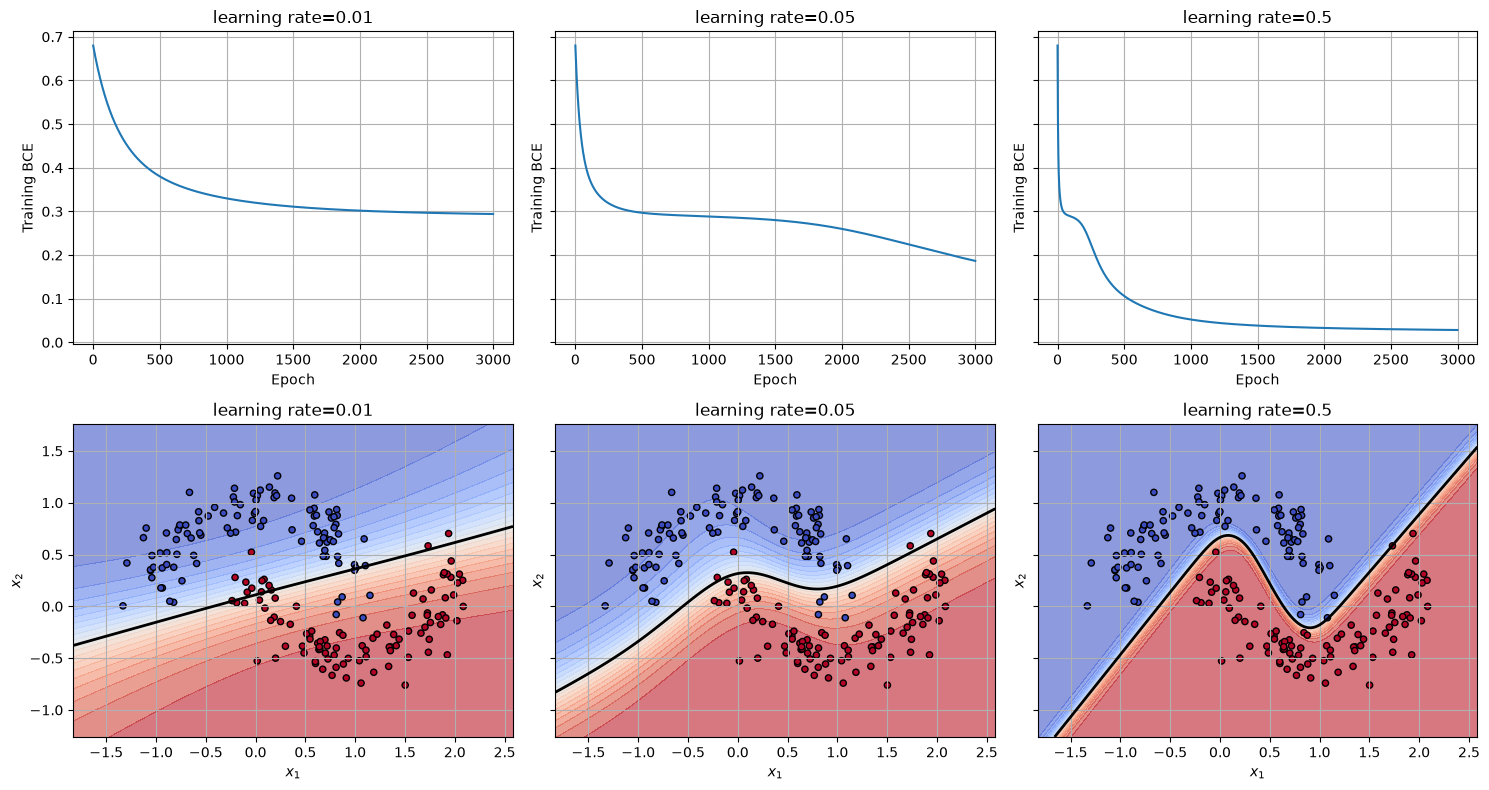

lr=0.05 for 30000 epochs: final train loss = 0.0284


lr=0.5 on 30*X: final train loss = 0.1456, std of the loss over the last 100 epochs = 0.0261


In [18]:
lr_initial = initialize_parameters(8, seed=17)
lr_runs = {}
for lr in (0.01, 0.05, 0.5):
    params, loss = train_model(X_train, y_train, lr_initial, learning_rate=lr, epochs=3000)
    lr_runs[f"learning rate={lr}"] = {
        "parameters": params,
        "loss": loss,
        "predict": lambda X, p=params: forward(X, **p)[0].ravel()}

lr_metrics = show_experiments(lr_runs)

# Small steps follow the same path more slowly: lr=0.05 for 10x the epochs.
long_params, long_loss = train_model(X_train, y_train, lr_initial, learning_rate=0.05, epochs=30000)
print(f"lr=0.05 for 30000 epochs: final train loss = {long_loss[-1]:.4f}")

# The same lr=0.5 on the same data with the inputs multiplied by 30 (different units).
scaled_params, scaled_loss = train_model(30 * X_train, y_train, lr_initial, learning_rate=0.5, epochs=3000)
print(f"lr=0.5 on 30*X: final train loss = {scaled_loss[-1]:.4f}, "
      f"std of the loss over the last 100 epochs = {scaled_loss[-100:].std():.4f}")

| learning rate | train loss | test loss | train acc | test acc |
|---|---|---|---|---|
| 0.01 | 0.2940 | 0.2155 | 0.8625 | 0.9050 |
| 0.05 | 0.1866 | 0.1348 | 0.9213 | 0.9550 |
| 0.5 | 0.0284 | 0.0144 | 0.9875 | 1.0000 |

All three models have the same architecture and start from the same arrays, so their capacity is identical: they can represent exactly the same boundaries. Only the step size changes, so every difference here comes from optimization.

Every curve first drops to the linear-fit level near 0.29 and sits on a plateau, and the boundary only curves after the model leaves it. With lr = 0.01 the model does not leave the plateau in 3000 epochs and ends with an almost straight boundary. With lr = 0.05 it leaves around epoch 1500 and is still improving at the end. With lr = 0.5 it leaves after about 250 epochs and reaches train loss 0.0284, with a boundary that follows both moons.

The slower models are unfinished. Small steps follow almost the same path, only more slowly: lr = 0.05 trained for 30000 epochs (ten times longer) ends at train loss 0.0284, the same value lr = 0.5 reached in 3000 epochs. The larger learning rate covered the same path in fewer epochs.

A learning rate that works here does not guarantee stable convergence on other data. The largest stable step depends on how sharply the loss curves, and that changes with the input scale, the data, the architecture and the batch size. In the extra run I multiplied the same inputs by 30, as if they were measured in different units. With the same lr = 0.5 the loss kept jumping (its standard deviation over the last 100 epochs is 0.0261) and ended at 0.146 instead of settling. The test accuracy of 1.0 at lr = 0.5 also comes from 200 points of one split. To choose a learning rate I would hold out a validation set from the training data and keep the test set for the final report.

## 20. A second hidden layer

The model becomes $2\rightarrow8\rightarrow8\rightarrow1$, with tanh in both hidden layers and a sigmoid output:
$$Z^{[1]}=XW^{[1]}+b^{[1]},\quad A^{[1]}=\tanh(Z^{[1]}),$$
$$Z^{[2]}=A^{[1]}W^{[2]}+b^{[2]},\quad A^{[2]}=\tanh(Z^{[2]}),$$
$$Z^{[3]}=A^{[2]}W^{[3]}+b^{[3]},\quad A^{[3]}=\sigma(Z^{[3]}).$$
Before training, the gradients of all six arrays are checked numerically on the first 16 training examples (seed 17, $\epsilon = 10^{-5}$) and against PyTorch autograd. Then a shallow (`2 → 8 → 1`) and a deep (`2 → 8 → 8 → 1`) model train with seed 17, lr 0.05 and 4000 epochs each.

Shapes of the six arrays:

| array | shape | entries |
|---|---|---|
| $W^{[1]}$ | $(2, 8)$ | 16 |
| $b^{[1]}$ | $(1, 8)$ | 8 |
| $W^{[2]}$ | $(8, 8)$ | 64 |
| $b^{[2]}$ | $(1, 8)$ | 8 |
| $W^{[3]}$ | $(8, 1)$ | 8 |
| $b^{[3]}$ | $(1, 1)$ | 1 |
| total | | 105 |

The gradients follow the same chain rule as the shallow network, with one more tanh layer in the middle. As before, the $dZ$ and $dA$ arrays are per example, and $1/m$ appears once in each parameter gradient.

Output layer (sigmoid with BCE, the same cancellation as before):

$$dZ^{[3]} = A^{[3]} - Y\ (m\times1),\qquad dW^{[3]} = \tfrac{1}{m}A^{[2]T}dZ^{[3]}\ (8\times1),\qquad db^{[3]} = \tfrac{1}{m}\textstyle\sum_i dZ^{[3]}_{i}\ (1\times1).$$

Second hidden layer:

$$dA^{[2]} = dZ^{[3]}W^{[3]T}\ (m\times8),\qquad dZ^{[2]} = dA^{[2]}\odot\left(1-\tanh^2(Z^{[2]})\right)\ (m\times8),$$

$$dW^{[2]} = \tfrac{1}{m}A^{[1]T}dZ^{[2]}\ (8\times8),\qquad db^{[2]} = \tfrac{1}{m}\textstyle\sum_i dZ^{[2]}_{i,:}\ (1\times8).$$

First hidden layer:

$$dA^{[1]} = dZ^{[2]}W^{[2]T}\ (m\times8),\qquad dZ^{[1]} = dA^{[1]}\odot\left(1-\tanh^2(Z^{[1]})\right)\ (m\times8),$$

$$dW^{[1]} = \tfrac{1}{m}X^{T}dZ^{[1]}\ (2\times8),\qquad db^{[1]} = \tfrac{1}{m}\textstyle\sum_i dZ^{[1]}_{i,:}\ (1\times8).$$

The error that reaches $Z^{[1]}$ has been multiplied by two tanh derivatives, each at most 1. If either layer saturates, these factors get close to zero and the first layer learns slowly.

The numerical check below covers every entry of all six arrays on the first 16 training examples. All relative errors are below $5\times10^{-11}$, and the PyTorch comparison agrees to about $10^{-17}$.

In [19]:
def initialize_deep(hidden1=8, hidden2=8, seed=17):
    rng = np.random.RandomState(seed)
    return {"W1": rng.randn(2, hidden1) * 0.5,
            "b1": np.zeros((1, hidden1)),
            "W2": rng.randn(hidden1, hidden2) * 0.5,
            "b2": np.zeros((1, hidden2)),
            "W3": rng.randn(hidden2, 1) * 0.5,
            "b3": np.zeros((1, 1))}


def forward_deep(X, parameters):
    Z1 = X @ parameters["W1"] + parameters["b1"]     # (m, h1)
    A1 = tanh(Z1)
    Z2 = A1 @ parameters["W2"] + parameters["b2"]    # (m, h2)
    A2 = tanh(Z2)
    Z3 = A2 @ parameters["W3"] + parameters["b3"]    # (m, 1)
    A3 = sigmoid(Z3)
    cache = {"X": X, "Z1": Z1, "A1": A1, "Z2": Z2, "A2": A2, "Z3": Z3, "A3": A3}
    return A3, cache


def backward_deep(y_true, cache, parameters):
    X = cache["X"]
    m = X.shape[0]
    Y = np.asarray(y_true, dtype=np.float64).reshape(-1, 1)

    dZ3 = cache["A3"] - Y                                   # (m, 1)
    dW3 = cache["A2"].T @ dZ3 / m                           # (h2, 1)
    db3 = np.sum(dZ3, axis=0, keepdims=True) / m            # (1, 1)

    dA2 = dZ3 @ parameters["W3"].T                          # (m, h2)
    dZ2 = dA2 * tanh_derivative(cache["Z2"])                # (m, h2)
    dW2 = cache["A1"].T @ dZ2 / m                           # (h1, h2)
    db2 = np.sum(dZ2, axis=0, keepdims=True) / m            # (1, h2)

    dA1 = dZ2 @ parameters["W2"].T                          # (m, h1)
    dZ1 = dA1 * tanh_derivative(cache["Z1"])                # (m, h1)
    dW1 = X.T @ dZ1 / m                                     # (2, h1)
    db1 = np.sum(dZ1, axis=0, keepdims=True) / m            # (1, h1)

    return {"dW1": dW1, "db1": db1, "dW2": dW2, "db2": db2, "dW3": dW3, "db3": db3}


def train_deep(X, y, initial_parameters, learning_rate=0.05, epochs=4000):
    parameters = {name: value.copy() for name, value in initial_parameters.items()}
    loss_history = np.zeros(epochs)
    for epoch in range(epochs):
        y_hat, cache = forward_deep(X, parameters)
        loss_history[epoch] = binary_cross_entropy(y, y_hat)
        grads = backward_deep(y, cache, parameters)
        for name in parameters:
            parameters[name] -= learning_rate * grads["d" + name]
    return parameters, loss_history


deep_initial = initialize_deep()
_, deep_cache = forward_deep(X_train[:16], deep_initial)
deep_analytical = backward_deep(y_train[:16], deep_cache, deep_initial)
deep_gradient_errors = check_gradients(
    deep_initial, deep_analytical,
    lambda p: binary_cross_entropy(y_train[:16], forward_deep(X_train[:16], p)[0]))
for name, error in deep_gradient_errors.items():
    print(f"Deep {name}: relative error = {error:.12e}")
    assert error < 1e-6, f"Deep gradient check failed for {name}"

Deep W1: relative error = 2.817154276826e-11
Deep b1: relative error = 4.413494424313e-11
Deep W2: relative error = 2.529680001868e-11
Deep b2: relative error = 1.653454892643e-11
Deep W3: relative error = 2.994035396044e-11
Deep b3: relative error = 7.297391678414e-12


**Autograd check.** The untrained NumPy parameters go into a PyTorch model, and all six gradients are compared on the same 16 examples. No optimizer steps are taken.

In [20]:
import torch

deep_torch = torch.nn.Sequential(
    torch.nn.Linear(deep_initial["W1"].shape[0], deep_initial["W1"].shape[1]),
    torch.nn.Tanh(),
    torch.nn.Linear(deep_initial["W2"].shape[0], deep_initial["W2"].shape[1]),
    torch.nn.Tanh(),
    torch.nn.Linear(deep_initial["W3"].shape[0], deep_initial["W3"].shape[1]),
    torch.nn.Sigmoid()).double()
with torch.no_grad():
    for number, layer_index in enumerate((0, 2, 4), start=1):
        deep_torch[layer_index].weight.copy_(torch.from_numpy(deep_initial[f"W{number}"].T))
        deep_torch[layer_index].bias.copy_(torch.from_numpy(deep_initial[f"b{number}"].ravel()))
deep_output_t = deep_torch(torch.tensor(X_train[:16], dtype=torch.float64))
deep_loss_t = torch.nn.BCELoss()(deep_output_t,
                                torch.tensor(y_train[:16].reshape(-1, 1), dtype=torch.float64))
deep_torch.zero_grad()
deep_loss_t.backward()
deep_torch_errors = {}
for number, layer_index in enumerate((0, 2, 4), start=1):
    for prefix, torch_gradient in (("W", deep_torch[layer_index].weight.grad.numpy().T),
                                    ("b", deep_torch[layer_index].bias.grad.numpy().reshape(1, -1))):
        name = f"d{prefix}{number}"
        deep_torch_errors[name] = np.max(np.abs(deep_analytical[name] - torch_gradient))
        print(f"Deep {name}: maximum autograd difference = {deep_torch_errors[name]:.12e}")
        np.testing.assert_allclose(deep_analytical[name], torch_gradient, atol=1e-10, rtol=1e-8)

Deep dW1: maximum autograd difference = 2.775557561563e-17
Deep db1: maximum autograd difference = 2.775557561563e-17
Deep dW2: maximum autograd difference = 2.775557561563e-17
Deep db2: maximum autograd difference = 2.775557561563e-17
Deep dW3: maximum autograd difference = 1.561251128379e-17
Deep db3: maximum autograd difference = 0.000000000000e+00


shallow 2-8-1 train_loss=0.1346 | test_loss=0.0988 | train_accuracy=0.9550 | test_accuracy=0.9650
deep 2-8-8-1 train_loss=0.0314 | test_loss=0.0190 | train_accuracy=0.9900 | test_accuracy=0.9900


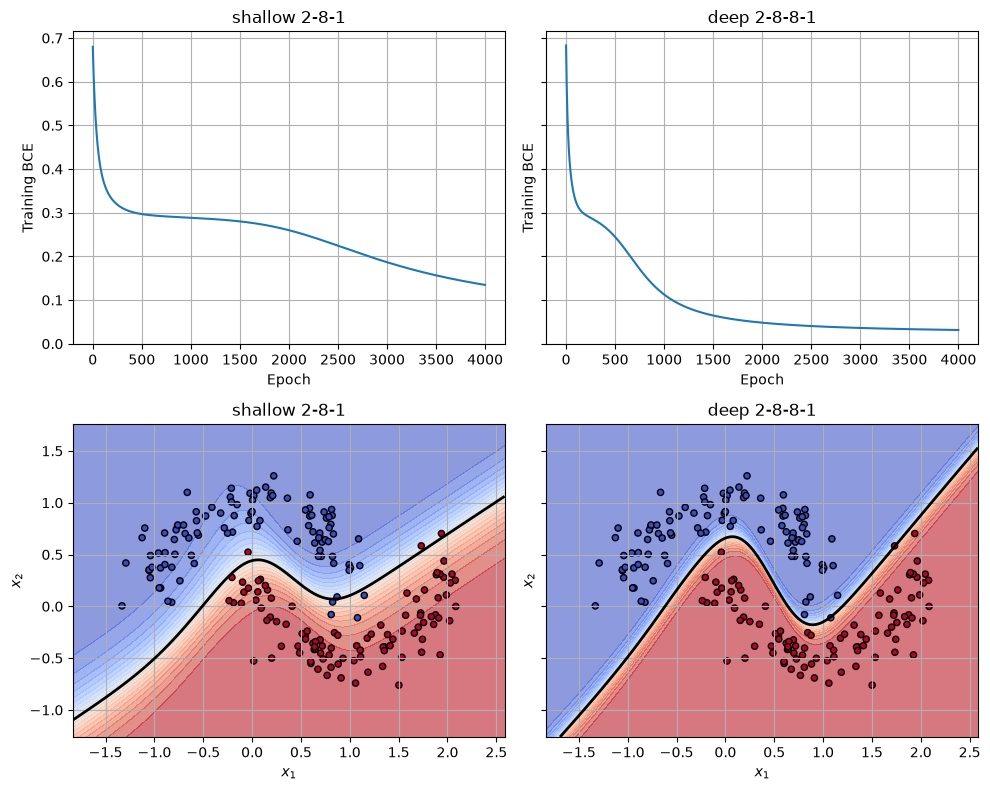

shallow 2-8-1 parameter count: 33
deep 2-8-8-1 parameter count: 105


In [21]:
shallow_params, shallow_loss = train_model(X_train, y_train, initialize_parameters(8, seed=17),
                                           learning_rate=0.05, epochs=4000)
deep_params, deep_loss = train_deep(X_train, y_train, initialize_deep(seed=17),
                                    learning_rate=0.05, epochs=4000)

depth_runs = {
    "shallow 2-8-1": {"parameters": shallow_params, "loss": shallow_loss,
                      "predict": lambda X: forward(X, **shallow_params)[0].ravel()},
    "deep 2-8-8-1": {"parameters": deep_params, "loss": deep_loss,
                     "predict": lambda X: forward_deep(X, deep_params)[0].ravel()}}
depth_metrics = show_experiments(depth_runs)


def count_parameters(parameters):
    return sum(value.size for value in parameters.values())


print(f"shallow 2-8-1 parameter count: {count_parameters(shallow_params)}")
print(f"deep 2-8-8-1 parameter count: {count_parameters(deep_params)}")

| model | parameters | train loss | test loss | train acc | test acc |
|---|---|---|---|---|---|
| shallow 2-8-1 | 33 | 0.1346 | 0.0988 | 0.9550 | 0.9650 |
| deep 2-8-8-1 | 105 | 0.0314 | 0.0190 | 0.9900 | 0.9900 |

With the same settings (seed 17, lr = 0.05, 4000 epochs), the deep model ends much lower. Its loss leaves the 0.29 plateau before epoch 500 and is almost flat after epoch 2000. The shallow model leaves the plateau only around epoch 1500 and is still falling at epoch 4000. The shallow boundary has the right shape but does not dip far enough between the moons, so it misclassifies blue points near the tip of the upper moon around $x_1 \approx 0.9$. The deep boundary follows both moons closely. The deep model also has more than three times as many parameters (105 against 33).

This run does not show that Two Moons needs depth. In Section 19 the same 2-8-1 network with lr = 0.5 reached train loss 0.0284, with 0.9875 train and 1.0 test accuracy, in 3000 epochs. The shallow model can represent a boundary as good as the deep one; at lr = 0.05 it had not reached it yet. So the gap in this comparison is mostly about optimization: within this budget the deeper network found the curved solution sooner. All of it comes from one seed and one learning rate, so it is not a general result about depth.

Extra depth need not help on a small dataset like this one. The boundary between the moons is one smooth curve, and a single layer of tanh units can already draw it, so extra capacity has little to add. With 800 noisy points, a bigger model also has more room to fit the overlap points, which would hurt test accuracy (neither model got that far here). Deeper networks can also be harder to train, because the gradient of the early layers passes through more tanh derivatives and weight matrices and can shrink or grow along the way. Capacity is about which functions a model can represent. Whether gradient descent finds a good one within the budget is a separate question, and this exercise measured the second.